<a href="https://colab.research.google.com/github/sam-ftw/NLP-Activity---Thirukural/blob/main/NLP_Thirukural.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q nltk rouge-score textstat sentence-transformers rapidfuzz

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re
import nltk
import textstat
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from rouge_score import rouge_scorer
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, Markdown

from collections import Counter

nltk.download('punkt', quiet=True)

True

In [3]:
kural = input("Enter the Thirukkural in Tamil: ")

human_translation = input("\nEnter the professional human translation: ")

ai_translation = input("\nEnter the AI translation: ")


print("\nThirukkural:")
print(kural)

print("\nHuman Translation:")
print(human_translation)

print("\nAI Translation:")
print(ai_translation)

Enter the Thirukkural in Tamil: இனிய உளவாக இன்னாத கூறல் கனிஇருப்பக் காய்கவர்ந் தற்று

Enter the professional human translation: When pleasant words are easy, bitter words to use, Is, leaving sweet ripe fruit, the sour unripe to choose.

Enter the AI translation: When kind words are within reach, to speak words that wound Is like leaving ripe, sweet fruit for sour, unripe fruit.

Thirukkural:
இனிய உளவாக இன்னாத கூறல் கனிஇருப்பக் காய்கவர்ந் தற்று

Human Translation:
When pleasant words are easy, bitter words to use, Is, leaving sweet ripe fruit, the sour unripe to choose.

AI Translation:
When kind words are within reach, to speak words that wound Is like leaving ripe, sweet fruit for sour, unripe fruit.


In [4]:
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

human_clean = preprocess(human_translation)
ai_clean = preprocess(ai_translation)

human_words = human_clean.split()
ai_words = ai_clean.split()

print("Human translation word count:", len(human_words))
print("AI translation word count:", len(ai_words))

print("\nHuman processed text:", human_clean)
print("\nAI processed text:", ai_clean)

Human translation word count: 19
AI translation word count: 21

Human processed text: when pleasant words are easy bitter words to use is leaving sweet ripe fruit the sour unripe to choose

AI processed text: when kind words are within reach to speak words that wound is like leaving ripe sweet fruit for sour unripe fruit


In [6]:
human_set = set(human_words)
ai_set = set(ai_words)

intersection = human_set.intersection(ai_set)
union = human_set.union(ai_set)

jaccard = len(intersection) / len(union) if union else 0

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(
    [human_clean, ai_clean]
)

tfidf_similarity = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0][0]


print(f"Jaccard Similarity: {jaccard:.4f} ({jaccard*100:.2f}%)")
print(f"TF-IDF Cosine Similarity: {tfidf_similarity:.4f} ({tfidf_similarity*100:.2f}%)")

print("\nCommon words:")
print(intersection)

print("\nWords unique to human translation:")
print(human_set - ai_set)

print("\nWords unique to AI translation:")
print(ai_set - human_set)

Jaccard Similarity: 0.4400 (44.00%)
TF-IDF Cosine Similarity: 0.5201 (52.01%)

Common words:
{'words', 'leaving', 'are', 'is', 'sour', 'unripe', 'to', 'sweet', 'fruit', 'when', 'ripe'}

Words unique to human translation:
{'the', 'use', 'pleasant', 'bitter', 'easy', 'choose'}

Words unique to AI translation:
{'like', 'kind', 'that', 'within', 'speak', 'for', 'wound', 'reach'}


In [7]:
smooth = SmoothingFunction().method1

bleu_human_to_ai = sentence_bleu(
    [human_words],
    ai_words,
    smoothing_function=smooth
)

bleu_ai_to_human = sentence_bleu(
    [ai_words],
    human_words,
    smoothing_function=smooth
)

scorer = rouge_scorer.RougeScorer(
    ['rouge1', 'rouge2', 'rougeL'],
    use_stemmer=True
)

rouge_results = scorer.score(
    human_clean,
    ai_clean
)


print(f"BLEU (AI against Human): {bleu_human_to_ai:.4f}")
print(f"BLEU (Human against AI): {bleu_ai_to_human:.4f}")

for metric, score in rouge_results.items():
    print(f"{metric.upper()} F1: {score.fmeasure:.4f}")

BLEU (AI against Human): 0.0360
BLEU (Human against AI): 0.0361
ROUGE1 F1: 0.6000
ROUGE2 F1: 0.1053
ROUGEL F1: 0.5000


BLEU and ROUGE measure textual overlap, not whether a translation correctly conveys the original Tamil meaning.

In [9]:
model = SentenceTransformer('all-MiniLM-L6-v2')

human_embedding = model.encode([human_translation])
ai_embedding = model.encode([ai_translation])

semantic_similarity = cosine_similarity(
    human_embedding,
    ai_embedding
)[0][0]


print(f"Sentence-BERT Similarity: {semantic_similarity:.4f}")
print(f"Percentage: {semantic_similarity * 100:.2f}%")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence-BERT Similarity: 0.7921
Percentage: 79.21%


Sentence-BERT measures semantic closeness, not translation correctness.

In [10]:
readability_metrics = {
    "Flesch Reading Ease": lambda x: textstat.flesch_reading_ease(x),
    "Flesch-Kincaid Grade": lambda x: textstat.flesch_kincaid_grade(x),
    "Gunning Fog Index": lambda x: textstat.gunning_fog(x),
    "Coleman-Liau Index": lambda x: textstat.coleman_liau_index(x),
    "Automated Readability Index": lambda x: textstat.automated_readability_index(x)
}

readability_results = []

for metric, function in readability_metrics.items():
    readability_results.append({
        "Metric": metric,
        "Human Translation": round(function(human_translation), 2),
        "AI Translation": round(function(ai_translation), 2)
    })

readability_df = pd.DataFrame(readability_results)

display(readability_df)

,Metric,Human Translation,AI Translation
0,Flesch Reading Ease,76.23,84.81
1,Flesch-Kincaid Grade,7.35,6.65
2,Gunning Fog Index,7.60,8.40
3,Coleman-Liau Index,8.28,8.48
4,Automated Readability Index,10.13,10.83


In [11]:
from difflib import SequenceMatcher

matcher = SequenceMatcher(
    None,
    human_words,
    ai_words
)


for tag, i1, i2, j1, j2 in matcher.get_opcodes():

    if tag == 'equal':
        print("MATCH:", ' '.join(human_words[i1:i2]))

    elif tag == 'replace':
        print("HUMAN:", ' '.join(human_words[i1:i2]))
        print("AI:   ", ' '.join(ai_words[j1:j2]))

    elif tag == 'delete':
        print("ONLY HUMAN:", ' '.join(human_words[i1:i2]))

    elif tag == 'insert':
        print("ONLY AI:", ' '.join(ai_words[j1:j2]))

MATCH: when
HUMAN: pleasant
AI:    kind
MATCH: words are
HUMAN: easy bitter
AI:    within reach to speak
MATCH: words
HUMAN: to use
AI:    that wound
MATCH: is
ONLY AI: like
MATCH: leaving
ONLY AI: ripe
MATCH: sweet
ONLY HUMAN: ripe
MATCH: fruit
HUMAN: the
AI:    for
MATCH: sour unripe
HUMAN: to choose
AI:    fruit


In [13]:
import textstat
import numpy as np
import pandas as pd
import re

def evaluate_translation(text):

    words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

    sentences = [
        s.strip() for s in re.split(r'[.!?]+', text)
        if s.strip()
    ]

    word_count = len(words)
    unique_words = set(words)

    return {
        "Word Count": word_count,

        "Unique Words": len(unique_words),

        "Type-Token Ratio": (
            len(unique_words) / word_count
            if word_count else 0
        ),

        "Average Word Length": (
            np.mean([len(w) for w in words])
            if words else 0
        ),

        "Average Sentence Length": (
            word_count / len(sentences)
            if sentences else 0
        ),

        "Flesch Reading Ease":
            textstat.flesch_reading_ease(text),

        "Flesch-Kincaid Grade":
            textstat.flesch_kincaid_grade(text),

        "Gunning Fog Index":
            textstat.gunning_fog(text),

        "Dale-Chall Score":
            textstat.dale_chall_readability_score(text),

        "Hapax Legomena Ratio": (
            sum(1 for w, c in __import__('collections').Counter(words).items() if c == 1)
            / word_count if word_count else 0
        )
    }


human_metrics = evaluate_translation(human_translation)
ai_metrics = evaluate_translation(ai_translation)

automated_results = pd.DataFrame({
    "Metric": human_metrics.keys(),
    "Human Translation": human_metrics.values(),
    "AI Translation": ai_metrics.values()
})

display(automated_results.round(3))

,Metric,Human Translation,AI Translation
0,Word Count,19.000,21.000
1,Unique Words,17.000,19.000
2,Type-Token Ratio,0.895,0.905
3,Average Word Length,4.421,4.429
4,Average Sentence Length,19.000,21.000
5,Flesch Reading Ease,76.234,84.806
6,Flesch-Kincaid Grade,7.346,6.648
7,Gunning Fog Index,7.600,8.400
8,Dale-Chall Score,7.072,7.686
9,Hapax Legomena Ratio,0.789,0.810


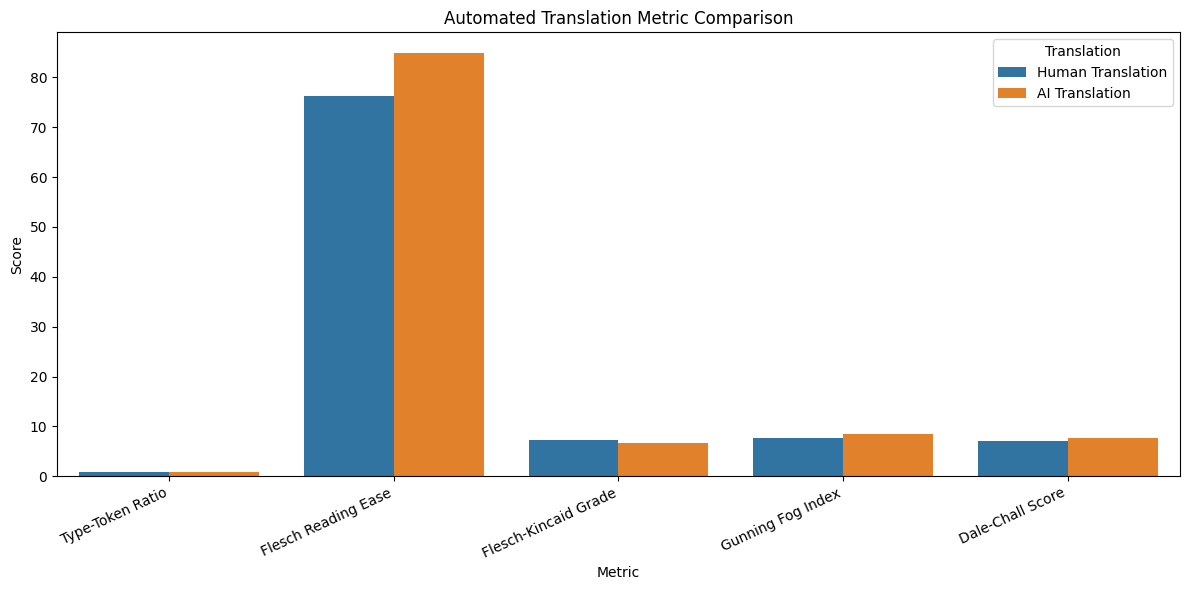

In [14]:
metrics_to_plot = [
    "Flesch Reading Ease",
    "Flesch-Kincaid Grade",
    "Gunning Fog Index",
    "Dale-Chall Score",
    "Type-Token Ratio"
]

plot_data = automated_results[
    automated_results["Metric"].isin(metrics_to_plot)
]

plot_data = plot_data.melt(
    id_vars="Metric",
    var_name="Translation",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Translation"
)

plt.title("Automated Translation Metric Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [15]:
for metric in human_metrics:

    h = human_metrics[metric]
    a = ai_metrics[metric]

    print(f"\n{metric}")
    print(f"Human: {h:.3f}")
    print(f"AI:    {a:.3f}")

    if metric == "Flesch Reading Ease":
        better = "Human" if h > a else "AI"
        print(f"More readable: {better}")

    elif metric in [
        "Flesch-Kincaid Grade",
        "Gunning Fog Index",
        "Dale-Chall Score"
    ]:
        better = "Human" if h < a else "AI"
        print(f"Lower reading complexity: {better}")

    else:
        print("Compare values as descriptive statistics.")


Word Count
Human: 19.000
AI:    21.000
Compare values as descriptive statistics.

Unique Words
Human: 17.000
AI:    19.000
Compare values as descriptive statistics.

Type-Token Ratio
Human: 0.895
AI:    0.905
Compare values as descriptive statistics.

Average Word Length
Human: 4.421
AI:    4.429
Compare values as descriptive statistics.

Average Sentence Length
Human: 19.000
AI:    21.000
Compare values as descriptive statistics.

Flesch Reading Ease
Human: 76.234
AI:    84.806
More readable: AI

Flesch-Kincaid Grade
Human: 7.346
AI:    6.648
Lower reading complexity: AI

Gunning Fog Index
Human: 7.600
AI:    8.400
Lower reading complexity: Human

Dale-Chall Score
Human: 7.072
AI:    7.686
Lower reading complexity: Human

Hapax Legomena Ratio
Human: 0.789
AI:    0.810
Compare values as descriptive statistics.
